## Visualize ensemble reconstruction results

In [1]:
import jax
jax.config.update('jax_platform_name', 'cpu')
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import sys 
sys.path.insert(1, '../')

import plotly.graph_objs as go
from plotly.offline import iplot

from jax import numpy as jnp
import numpy as np

from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

In [2]:
pm_seed = 2
num_its = 25

# i_list = range(100)
# i_list = range(1)
i_list = list(range(0, 0+num_its)) + list(range(25, 25+num_its)) + list(range(50, 50+num_its)) + list(range(75, 75+num_its))
save_dirs = ['../../exp/vol_jwst%d_L_2_Lz_5_proj_gg_shape_sigma_0.25_lam_0.03/%d'%(pm_seed, i) for i in i_list]

# wiener_recon = jnp.load('../../wiener_recon/pm%d_wiener.npy'%pm_seed).transpose((1,2,0))
wiener_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/wiener_jwst_2.npy').transpose(1, 2, 0)
print(wiener_recon.shape)
ddpm_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_recon_jwst_2_map.npy')[:, 30:99, :69] .transpose(1, 2, 0)
density_paths = [save_dir + '/density/density_500.p' for save_dir in save_dirs]
# density_paths_2 = [save_dir + '/density/density_500.p' for save_dir in save_dirs_2]

res = 69

CUDA backend failed to initialize: jaxlib/cuda/versions_helpers.cc:98: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


(69, 69, 20)


In [3]:
def mean_subtract(vol, axis=(0,1)): 
    return vol - jnp.mean(vol, axis=axis, keepdims=True)

densities = [mean_subtract(jnp.load(density_path).reshape(res, res, 20)) for density_path in density_paths]
densities_arr = jnp.array(densities)

density_gt = jnp.load(save_dirs[-1] + '/../density_gt.p').reshape(res, res, 20)

pws = jnp.load(save_dirs[0] + '/../pws.npy')
pws_ein = pws.reshape(-1, res, res, 20)

density_gt = mean_subtract(density_gt)
ddpm_recon = mean_subtract(ddpm_recon)
wiener_recon = mean_subtract(wiener_recon)

print(ddpm_recon.shape)
print(wiener_recon.shape)

(69, 69, 20)
(69, 69, 20)


In [4]:
k_gt = jnp.einsum('nhwc,hwc->nhw', pws_ein, density_gt).mean(0)
k_nn = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, densities_arr).mean(1)
k_dm = jnp.einsum('nhwc,hwc->nhw', pws_ein, ddpm_recon).mean(0)
k_wiener = jnp.einsum('nhwc,hwc->nhw', pws_ein, wiener_recon).mean(0)

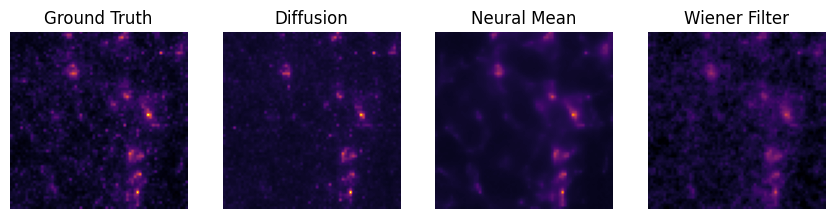

In [5]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 6, 1)
plt.imshow(k_gt, cmap='inferno')
plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 6, 2)
plt.imshow(k_dm, cmap='inferno', vmin=k_gt.min(), vmax=k_gt.max())
plt.title('Diffusion')
plt.axis('off')

plt.subplot(1, 6, 3)
plt.imshow(k_nn.mean(0), cmap='inferno', vmin=k_gt.min(), vmax=k_gt.max())
plt.title('Neural Mean')
plt.axis('off')

plt.subplot(1, 6, 4)
plt.imshow(k_wiener, cmap='inferno', vmin=k_gt.min(), vmax=k_gt.max())
plt.title('Wiener Filter')
plt.axis('off')

plt.show()

In [6]:
densities_median = jnp.median(densities_arr, axis=0)
densities_mean = jnp.mean(densities_arr, axis=0)
densities_std = jnp.std(densities_arr, axis=0)

print(densities_mean.shape)

(69, 69, 20)


-1.3267472 10


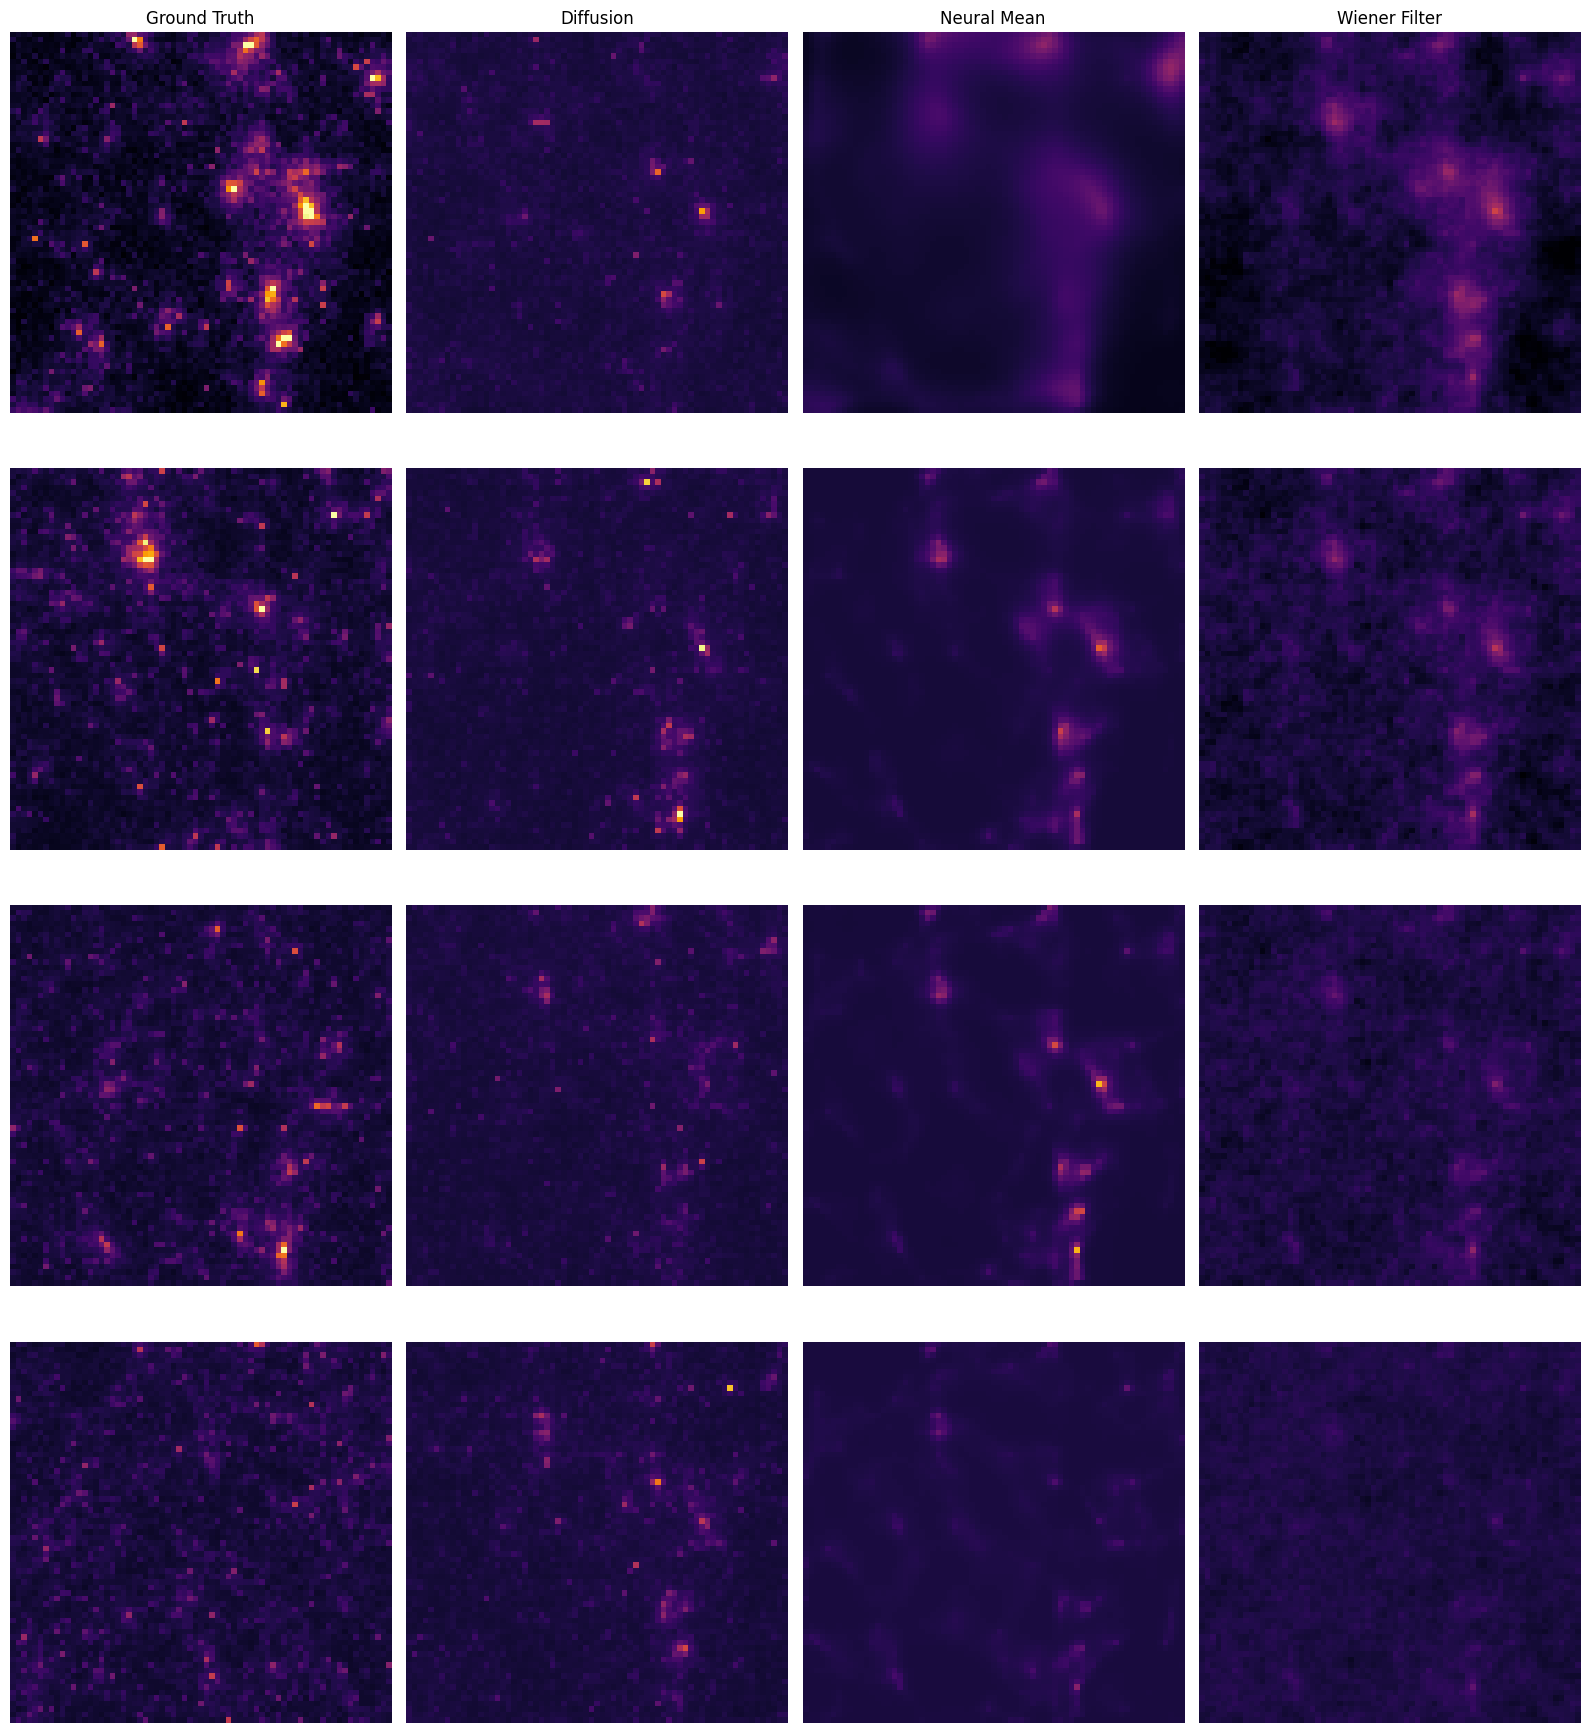

In [7]:
plt.figure(figsize=(16, 18))

slice_avg = lambda vol: vol[..., :12].reshape(res, res, 4, 3).mean(-1)

norm_fn = lambda x: x

vmin = norm_fn(slice_avg(density_gt)).min()
# vmax = norm_fn(slice_avg(density_gt)).max()
vmax = 10

print(vmin, vmax)

for i in range(4): 
    plt.subplot(4, 4, i*4+1)
    plt.imshow(norm_fn(slice_avg(density_gt)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Ground Truth')
    plt.axis('off')

    plt.subplot(4, 4, i*4+2)
    plt.imshow(norm_fn(slice_avg(ddpm_recon)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Diffusion')
    plt.axis('off')

    plt.subplot(4, 4, i*4+3)
    plt.imshow(norm_fn(slice_avg(densities_mean)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Neural Mean')
    plt.axis('off')

    plt.subplot(4, 4, i*4+4)
    plt.imshow(norm_fn(slice_avg(wiener_recon)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Wiener Filter')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
def norm_fro(arr): 
    return jnp.sqrt(jnp.sum(jnp.square(arr)))

def pearson_cc(vol1, vol2): 
    vol2 = vol2.reshape(vol1.shape)
    return jnp.sum(vol1 * vol2) / (norm_fro(vol1) * norm_fro(vol2))

def optimal_blur_slice(density_gt, density_recon, sigma_xys, sigma_zs, slice_idx):
    optimal_cc = -100.
    optimal_density_gt = None 
    optimal_sig_xy = None 
    optimal_sig_z = None
    for sig_xy in sigma_xys: 
        for sig_z in sigma_zs: 
            density_gt_blurred = gaussian_filter(density_gt, (sig_xy, sig_xy, sig_z))
            cc = pearson_cc(density_gt_blurred[...,slice_idx], density_recon[...,slice_idx])
            if cc > optimal_cc: 
                optimal_cc = cc
                optimal_density_gt = density_gt_blurred 
                optimal_sig_xy = sig_xy 
                optimal_sig_z = sig_z 
    return optimal_cc, optimal_density_gt, optimal_sig_xy, optimal_sig_z


In [9]:
print(pearson_cc(densities_median[..., :12], density_gt[..., :12]))
print(pearson_cc(densities_mean[..., :12], density_gt[..., :12]))
print(pearson_cc(wiener_recon[..., :12], density_gt[..., :12]))

0.1913225
0.35857412
0.29732698


In [10]:
sigma_xys = [2]
sigma_zs = jnp.linspace(0., 4., num=50)

optimal_sig_xys_median = []
optimal_sig_zs_median = []
optimal_ccs_median = []
optimal_density_gts_median = []
for i in tqdm(range(12)):
    optimal_cc, optimal_density_gt, optimal_sig_xy, optimal_sig_z = optimal_blur_slice(density_gt, densities_median, sigma_xys, sigma_zs, i)
    optimal_sig_xys_median.append(optimal_sig_xy)
    optimal_sig_zs_median.append(optimal_sig_z)
    optimal_ccs_median.append(optimal_cc)
    optimal_density_gts_median.append(optimal_density_gt[...,i])
optimal_density_gt_median = jnp.stack(optimal_density_gts_median, axis=-1)

optimal_sig_xys_wiener = []
optimal_sig_zs_wiener = []
optimal_ccs_wiener = []
optimal_density_gts_wiener = []
for i in tqdm(range(12)):
    optimal_cc, optimal_density_gt, optimal_sig_xy, optimal_sig_z = optimal_blur_slice(density_gt, wiener_recon, sigma_xys, sigma_zs, i)
    optimal_sig_xys_wiener.append(optimal_sig_xy)
    optimal_sig_zs_wiener.append(optimal_sig_z)
    optimal_ccs_wiener.append(optimal_cc)
    optimal_density_gts_wiener.append(optimal_density_gt[...,i])
optimal_density_gt_wiener = jnp.stack(optimal_density_gts_wiener, axis=-1)

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

In [37]:
print(density_gt.min(), densities_median.min())

-2.678738 -1.7281177


In [38]:
vmax1 = densities_mean[..., :12].max()
vmin = min(density_gt.min(), densities_median.min())
print(vmin)


-2.678738


## Vertical plots

In [39]:
def make_slice_plots_trunc_2_vert(eta_true, res_eta, vmin, vmax, writer, i, title, cmap='inferno', set_title=False, ftsize=36, use_cbar=False, full=False): 
    if full: 
        eta_slice = eta_true[...,:12]
        fig, axes = plt.subplots(12, 1, figsize=(5., 45.))
    else:
        eta_slice = eta_true[...,:12].reshape(res_eta, res_eta, 4, -1).mean(-1)
        fig, axes = plt.subplots(4, 1, figsize=(5., 15.))
    if vmin is None: 
        vmin = eta_slice.min() 
    if vmax is None: 
        vmax = eta_slice.max()

    for j in range(eta_slice.shape[-1]):  
        ax = axes[j]
        ax.set_xlim([0, res_eta - 1])
        ax.set_ylim([0, res_eta - 1])
        if set_title: ax.set_ylabel('Region %d'%j, size=ftsize)

        heatmap_im = ax.imshow(eta_slice[:, :, j], vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_xticks([])
        ax.set_yticks([])
	
    if use_cbar:
        cbar = fig.colorbar(heatmap_im, ax=axes.ravel().tolist(), ticks=[vmin, 0, vmax])
        cbar.ax.set_yticklabels([f'{vmin: .2f}',0, f'{vmax: .2f}'])
        cbar.ax.tick_params(labelsize=ftsize)
    axes[0].set_title(title, size=ftsize)
    # cbar = fig.colorbar(heatmap_im, cax=axes[-1], orientation='vertical', ticks=[vmin, 0, vmax], fraction=0.03, pad=0.04)

    # fig.tight_layout()
    if writer is not None:
        writer.add_figure(title+' Slice Plot', fig, i)
    else: 
        plt.show()
    plt.close()

def make_slice_plots_trunc_2_vert_cc(eta_true, res_eta, vmin, vmax, writer, i, title, ccs, cmap='inferno', set_title=False, ftsize=36, use_cbar=False, full=False): 
    if full: 
        eta_slice = eta_true[...,:12]
        fig, axes = plt.subplots(12, 1, figsize=(5., 45.))
    else:
        eta_slice = eta_true[...,:12].reshape(res_eta, res_eta, 4, -1).mean(-1)
        fig, axes = plt.subplots(4, 1, figsize=(5., 15.))
    if vmin is None: 
        vmin = eta_slice.min() 
    if vmax is None: 
        vmax = eta_slice.max()

    for j in range(eta_slice.shape[-1]):  
        ax = axes[j]
        ax.set_xlim([0, res_eta - 1])
        ax.set_ylim([0, res_eta - 1])
        if set_title: ax.set_ylabel('Region %d'%j, size=ftsize)

        heatmap_im = ax.imshow(eta_slice[:, :, j], vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_xticks([])
        ax.set_yticks([])

        plt.text(0.97, 0.87, f'{ccs[j]: .2f}',
		   		fontsize=ftsize,
		   		color='white',
                horizontalalignment='right',
                verticalalignment='center',
                transform = ax.transAxes)
	
    if use_cbar:
        cbar = fig.colorbar(heatmap_im, ax=axes.ravel().tolist(), ticks=[vmin, 0, vmax])
        cbar.ax.set_yticklabels([f'{vmin: .2f}',0, f'{vmax: .2f}'])
        cbar.ax.tick_params(labelsize=ftsize)
    axes[0].set_title(title, size=ftsize)

    if writer is not None:
        writer.add_figure(title+' Slice Plot', fig, i)
    else: 
        plt.show()
    plt.close()

In [40]:
optimal_sig_zs_median_slice = jnp.reshape(jnp.array(optimal_sig_zs_median), (4, 3)).mean(1)
optimal_sig_zs_wiener_slice = jnp.reshape(jnp.array(optimal_sig_zs_wiener), (4, 3)).mean(1)

In [41]:
optimal_density_gt_median = jnp.array(optimal_density_gts_median).transpose(1, 2, 0)
optimal_density_gt_wiener = jnp.array(optimal_density_gts_wiener).transpose(1, 2, 0)

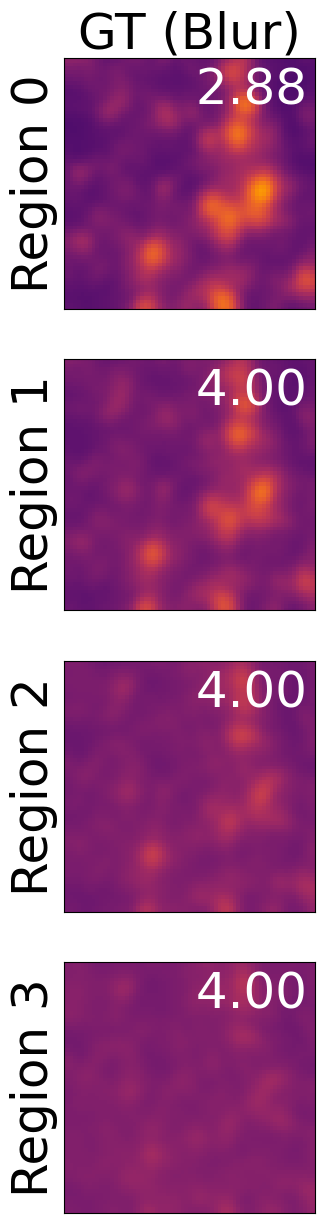

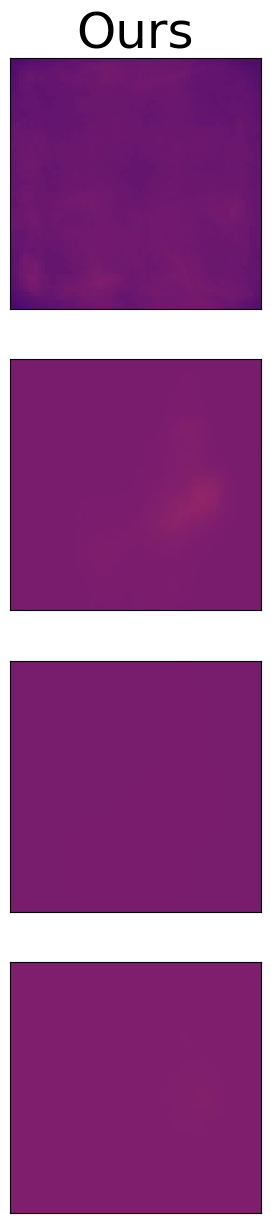

In [45]:
make_slice_plots_trunc_2_vert_cc(jnp.arcsinh(optimal_density_gt_median), res, jnp.arcsinh(vmin), jnp.arcsinh(vmax1), None, 0, 'GT (Blur)', optimal_sig_zs_median_slice, set_title=True, full=False)
make_slice_plots_trunc_2_vert(jnp.arcsinh(densities_median), res, jnp.arcsinh(vmin), jnp.arcsinh(vmax1), None, 0, 'Ours', set_title=False, full=False)

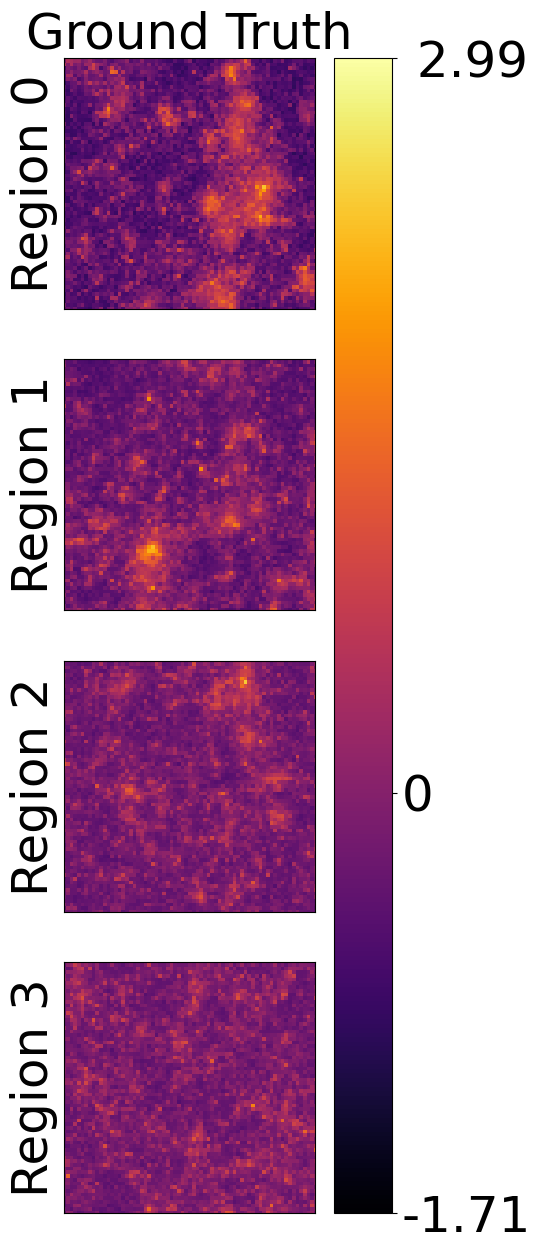

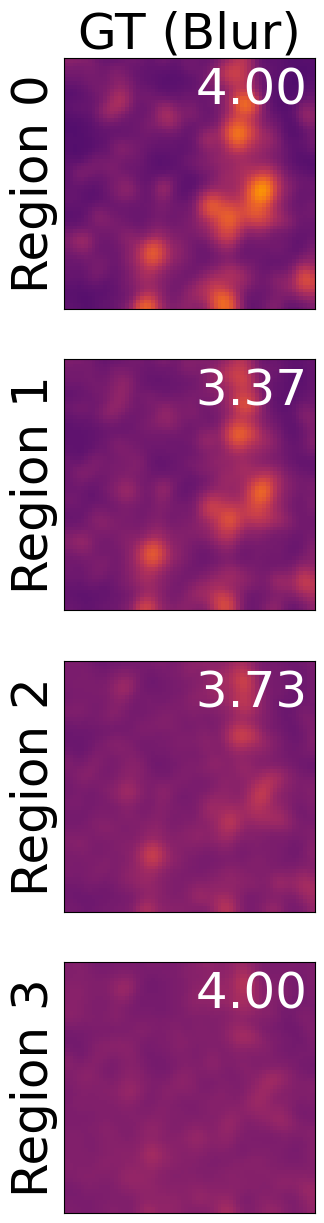

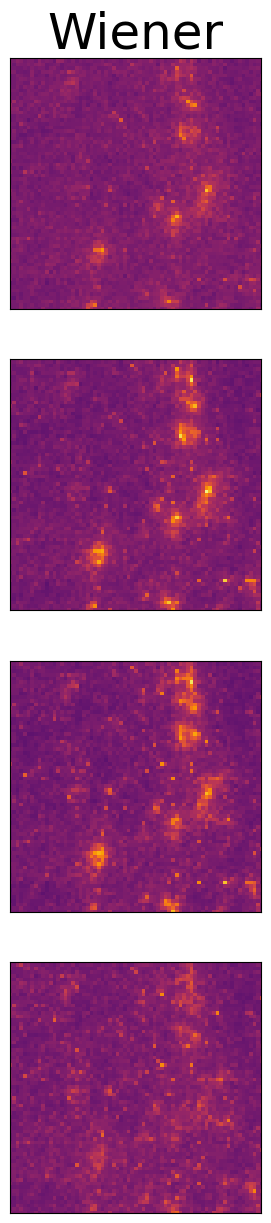

In [43]:
make_slice_plots_trunc_2_vert(jnp.arcsinh(density_gt), res, jnp.arcsinh(vmin), jnp.arcsinh(vmax1), None, 0, 'Ground Truth', set_title=True, use_cbar=True, full=False)
make_slice_plots_trunc_2_vert_cc(jnp.arcsinh(optimal_density_gt_wiener), res, jnp.arcsinh(vmin), jnp.arcsinh(vmax1), None, 0, 'GT (Blur)', optimal_sig_zs_wiener_slice, set_title=True, full=False)
make_slice_plots_trunc_2_vert(jnp.arcsinh(wiener_recon), res, jnp.arcsinh(vmin), jnp.arcsinh(vmax1), None, 0, 'Wiener', set_title=False, full=False)

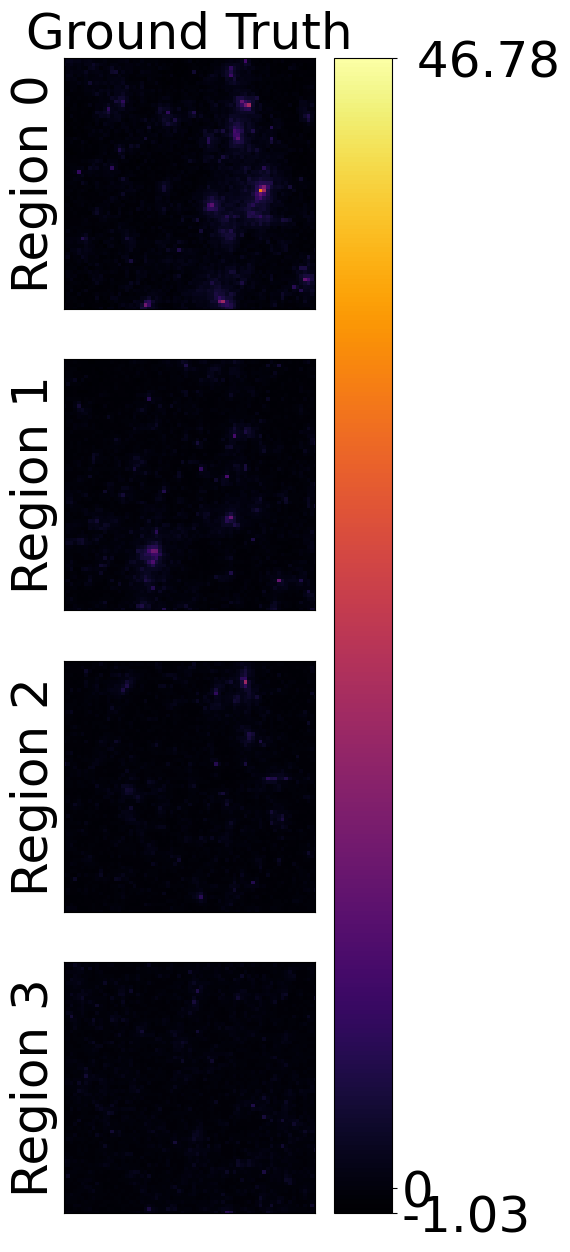

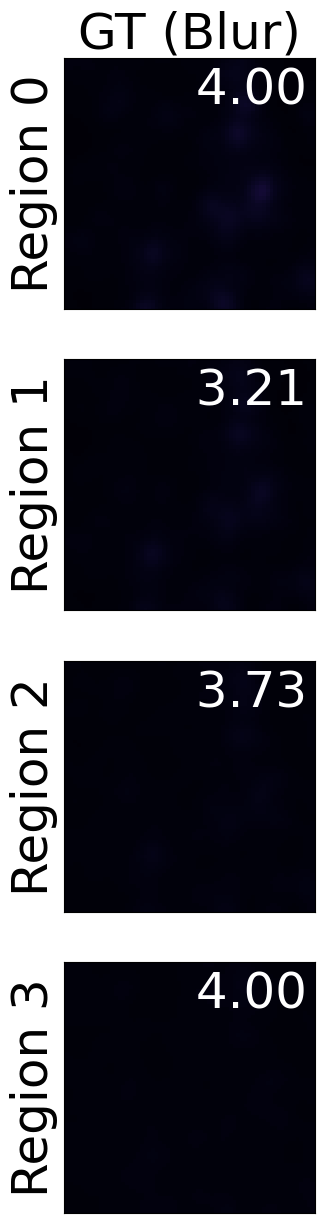

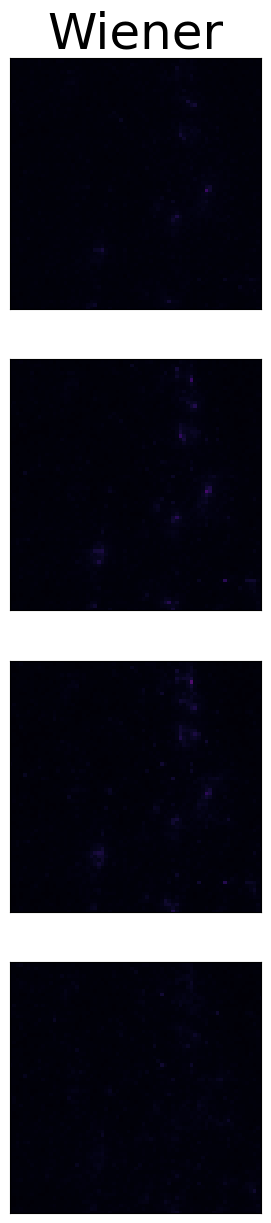

In [36]:
make_slice_plots_trunc_2_vert(density_gt, res, vmin, vmax1, None, 0, 'Ground Truth', set_title=True, use_cbar=True, full=False)
# make_slice_plots_trunc_2_vert_cc(optimal_density_gt, res, vmin, vmax1, None, 0, 'GT (Blurred)', optimal_sig_zs_slice, set_title=True)
# make_slice_plots_trunc_2_vert(densities_mean, res, vmin, vmax1, None, 0, 'Mean Recon', set_title=False)
make_slice_plots_trunc_2_vert_cc(optimal_density_gt_wiener, res, vmin, vmax1, None, 0, 'GT (Blur)', optimal_sig_zs_wiener_slice, set_title=True, full=False)
make_slice_plots_trunc_2_vert(wiener_recon, res, vmin, vmax1, None, 0, 'Wiener', set_title=False, full=False)

## Measure Power Spectra

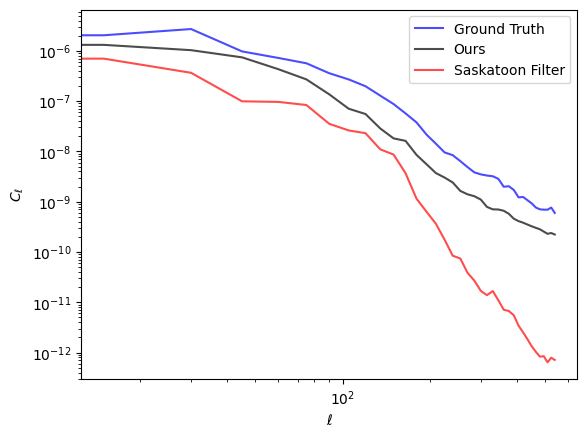

In [18]:
from shear.planes import *
planes_dict = jnp.load('../pm_fields/pm%d.npy'%pm_seed, allow_pickle=True)
dz, r, a = unpack_lensplanes(planes_dict)

def radial_profile(data):
  """
  Compute the radial profile of 2d image
  :param data: 2d image
  :return: radial profile
  """
  center = data.shape[0]/2
  y, x = jnp.indices((data.shape))
  r = jnp.sqrt((x - center)**2 + (y - center)**2)
  r = r.astype('int32')

  tbin = jnp.bincount(r.ravel(), data.ravel())
  nr = jnp.bincount(r.ravel())
  radialprofile = tbin / nr
  return radialprofile

def measure_power_spectrum(map_data, pixel_size):
  """
  measures power 2d data
  :param power: map (nxn)
  :param pixel_size: pixel_size (rad/pixel)
  :return: ell
  :return: power spectrum
  
  """
  data_ft = jnp.fft.fftshift(jnp.fft.fft2(map_data)) / map_data.shape[0]
  nyquist = int(map_data.shape[0]/2)
  power_spectrum_1d =  radial_profile(jnp.real(data_ft*jnp.conj(data_ft)))[:nyquist] * (pixel_size)**2
  k = np.arange(power_spectrum_1d.shape[0])
  ell = 2. * np.pi * k / pixel_size / 360
  return ell, power_spectrum_1d

resolution = 300 / 75
pixel_size = np.pi * resolution / 180. / 60. #rad/pixel



# for i in range(3, 13):
i = 10

# noise_key = jax.random.PRNGKey(0)
# noise_std = jnp.std(density_gt[..., i])
# noise_map = jax.random.normal(noise_key, shape=density_gt[...,i].shape)

# ell_map, ps_map = measure_power_spectrum(noise_map, pixel_size)
# plt.loglog(ell_map, ps_map, alpha=(i-3)/10, c='lightgrey', label='White Gaussian Noise')

ell_map, ps_map = measure_power_spectrum(density_gt[...,i], pixel_size)
plt.loglog(ell_map, ps_map, alpha=(i-3)/10, c='blue', label='Ground Truth')
ell_map, ps_map = measure_power_spectrum(densities_mean[...,i], pixel_size)
plt.loglog(ell_map, ps_map, alpha=(i-3)/10, c='black', label='Ours')
ell_map, ps_map = measure_power_spectrum(wiener_recon[...,i], pixel_size)
plt.loglog(ell_map, ps_map, alpha=(i-3)/10, c='red', label='Saskatoon Filter')

plt.xlabel(r'$\ell$')
plt.ylabel(r'$C_\ell$')

plt.legend()
plt.show()